# Experiment Control Systems

Python companion to the AMO Toolkit page [Experiment Control Systems](https://amotoolkit.com/pages/control-systems.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/control-systems.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. Signal budget
How fine and how fast each channel can be. Formulas as on the page: DAC step = range/2<sup>bits</sup>; DDS step = f<sub>clk</sub>/2<sup>N</sup>; AOM optical rise time τ ≈ 0.65 d/V and modulation bandwidth ≈ 0.35/τ (Isomet AN2600); coax delay ≈ 5 ns/m.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def budget(bits=16, span_V=20, rate_MSs=1, ramp_ms=10, clk_MHz=1000, ftw_bits=32, beam_mm=0.5, v_mm_us=4.2, cable_m=3):
    tau = 0.65 * beam_mm * 1e-3 / (v_mm_us * 1e3)
    return dict(dac_step_uV=span_V / 2**bits * 1e6, ramp_points=int(rate_MSs * 1e6 * ramp_ms * 1e-3),
                dds_step_mHz=clk_MHz * 1e6 / 2**ftw_bits * 1e3, nyquist_MHz=clk_MHz / 2,
                aom_rise_ns=tau * 1e9, aom_bw_MHz=0.35 / tau / 1e6, coax_delay_ns=cable_m * 5)

b = budget()     # page defaults (TeO2 longitudinal, 4.2 mm/µs)
for k, v in b.items():
    print(f"{k:>14} = {v:.4g}")
print(f"\nA 1 G/V coil driver: field step = {b['dac_step_uV']*1e-6*1e3:.3f} mG per DAC step")

   dac_step_uV = 305.2
   ramp_points = 1e+04
  dds_step_mHz = 232.8
   nyquist_MHz = 500
   aom_rise_ns = 77.38
    aom_bw_MHz = 4.523
 coax_delay_ns = 15

A 1 G/V coil driver: field step = 0.305 mG per DAC step

## 2. Pulse shape and spectrum
Envelopes of total length T, optionally smoothed by an AOM edge (Gaussian, 10–90% rise = 2.563 σ), then a numerical Fourier transform. The page's metrics: first side-lobe level, the half-width at −20 dB, and the power at a neighbouring transition.

   square: side lobe  -13.3 dB, −20 dB half-width   90.6 kHz, at 200 kHz  -42.2 dB
     hann: side lobe  -31.5 dB, −20 dB half-width  165.6 kHz, at 200 kHz -120.0 dB
    gauss: side lobe  -56.7 dB, −20 dB half-width  204.7 kHz, at 200 kHz  -19.2 dB
 blackman: side lobe  -58.1 dB, −20 dB half-width  198.4 kHz, at 200 kHz  -20.4 dB

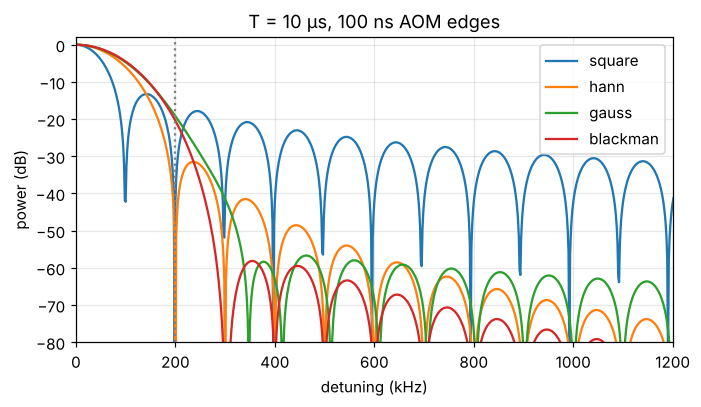

In [2]:
def envelope(shape, T, rise, N=8192):
    dt = T / 128; t = (np.arange(N) - N // 2) * dt; u = t / T + 0.5
    inside = (u >= 0) & (u <= 1)
    e = np.zeros(N)
    if shape == "square": e[inside] = 1
    elif shape == "hann": e[inside] = np.sin(np.pi * u[inside]) ** 2
    elif shape == "gauss": e[inside] = np.exp(-((u[inside] - 0.5) ** 2) / (2 * (1 / 6) ** 2))
    else: e[inside] = 0.42 - 0.5 * np.cos(2 * np.pi * u[inside]) + 0.08 * np.cos(4 * np.pi * u[inside])
    if rise > 0:
        sig = rise / 2.563 / dt; R = int(np.ceil(4 * sig)); k = np.arange(-R, R + 1)
        ker = np.exp(-k**2 / (2 * sig**2)); e = np.convolve(e, ker / ker.sum(), mode="same")
    return t, e, dt

def spectrum(shape="square", T=10e-6, rise=100e-9, nb=200e3):
    t, e, dt = envelope(shape, T, rise)
    F = np.fft.fft(e); P = np.abs(F[: len(e) // 2]) ** 2 / abs(F[0]) ** 2
    df = 1 / (len(e) * dt); f = np.arange(len(P)) * df
    iz = 1
    while iz < len(P) - 1 and not (P[iz] < P[iz - 1] and P[iz] <= P[iz + 1]): iz += 1
    i20 = np.argmax(P <= 0.01)
    return f, P, dict(side_lobe_dB=10 * np.log10(P[iz:].max()), half_width_20dB_kHz=i20 * df / 1e3,
                      at_neighbour_dB=10 * np.log10(max(P[int(round(nb / df))], 1e-12)))

res = {}
for shape in ("square", "hann", "gauss", "blackman"):
    f, P, m = spectrum(shape); res[shape] = m
    plt.plot(f / 1e3, 10 * np.log10(np.maximum(P, 1e-12)), label=shape)
    print(f"{shape:>9}: side lobe {m['side_lobe_dB']:6.1f} dB, −20 dB half-width {m['half_width_20dB_kHz']:6.1f} kHz, at 200 kHz {m['at_neighbour_dB']:6.1f} dB")
plt.xlim(0, 1200); plt.ylim(-80, 2); plt.axvline(200, c="gray", ls=":")
plt.xlabel("detuning (kHz)"); plt.ylabel("power (dB)"); plt.legend(); plt.title("T = 10 µs, 100 ns AOM edges")

**Course problem (week 7):** find the shortest Blackman pulse that keeps the drive at a 200 kHz neighbour below −40 dB:

In [3]:
for T_us in np.arange(10, 40, 0.5):
    if spectrum("blackman", T=T_us * 1e-6)[2]["at_neighbour_dB"] < -40:
        print(f"Blackman: T ≥ {T_us} µs"); break

Blackman: T ≥ 13.0 µs

## 3. Check against the page

In [4]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

ours = dict(b, sq_side=res["square"]["side_lobe_dB"], sq_hw=res["square"]["half_width_20dB_kHz"], sq_nb=res["square"]["at_neighbour_dB"],
            bk_side=res["blackman"]["side_lobe_dB"], bk_hw=res["blackman"]["half_width_20dB_kHz"], bk_nb=res["blackman"]["at_neighbour_dB"])
DECIMALS = dict(sq_side=1, sq_hw=1, sq_nb=1, bk_side=1, bk_hw=1, bk_nb=1)
page = dict(dac_step_uV=305, ramp_points=10000, dds_step_mHz=233, nyquist_MHz=500, aom_rise_ns=77.4, aom_bw_MHz=4.52,
            coax_delay_ns=15, sq_side=-13.3, sq_hw=90.6, sq_nb=-42.2, bk_side=-58.1, bk_hw=198.4, bk_nb=-20.4)
check(ours, page)

 dac_step_uV: notebook 305.2        page 305        OK
 ramp_points: notebook 1e+04        page 10000      OK
dds_step_mHz: notebook 232.8        page 233        OK
 nyquist_MHz: notebook 500          page 500        OK
 aom_rise_ns: notebook 77.38        page 77.4       OK
  aom_bw_MHz: notebook 4.523        page 4.52       OK
coax_delay_ns: notebook 15           page 15         OK
     sq_side: notebook -13.26       page -13.3      OK
       sq_hw: notebook 90.62        page 90.6       OK
       sq_nb: notebook -42.22       page -42.2      OK
     bk_side: notebook -58.14       page -58.1      OK
       bk_hw: notebook 198.4        page 198.4      OK
       bk_nb: notebook -20.43       page -20.4      OK
All values match the page.